# 05 — Temporal Convolutional Network (TCN)

**Purpose.** Train a causal dilated TCN on the same 24-hour windows as the LSTM.

**Inputs.** Sequence arrays from notebook 02.

**Outputs.** `models/tcn.pt`, `results/predictions_tcn.csv`, `results/tables/metrics_tcn.csv`.


In [1]:
# Shared deep-learning setup: frozen splits, GPU if available, one global seed.
from pathlib import Path
import os, sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

PROJECT_ROOT = Path.cwd().parent
os.environ["MPLCONFIGDIR"] = str(PROJECT_ROOT / ".mplconfig")
sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import (
    SEED, set_seed, print_library_versions, ensure_dirs, save_fig,
    get_torch_device, WindowSequenceDataset, load_sequence_split,
    downsample_indices, predict_torch_model, count_parameters, file_size_mb,
    classification_metrics, choose_threshold_max_f1, early_detection_metrics,
    metrics_to_row, save_metrics_table, save_predictions,
    plot_confusion_heatmap, plot_roc_pr,
    permutation_importance_torch, time_step_importance_torch,
)
from src.torch_models import TCNClassifier, train_sequence_model

set_seed(SEED)
print("SEED =", SEED)
print_library_versions()
PATHS = ensure_dirs(PROJECT_ROOT)
DEVICE = get_torch_device()
WINDOW = json.load(open(PATHS["processed"] / "sequence_config.json"))["window"]
print("WINDOW", WINDOW)


SEED = 42
python 3.9.6 (default, Oct 19 2026, 19:18:13)  [Clang 21.0.0 (clang-2100.4.1.1)]
numpy        2.0.2
pandas       2.3.3
sklearn      1.6.1
xgboost      2.1.4
torch        2.8.0
shap         0.49.1
optuna       5.0.0
matplotlib   3.9.4
seaborn      0.13.2
Using device: cpu
WINDOW 24


## Model-specific EDA: receptive field and causality


kernel=3, dilations=1,2,4,8, two convs/block
receptive field = 61 window = 24
covers window? True
 block  dilation  receptive_field_after_block
     1         1                            5
     2         2                           13
     3         4                           29
     4         8                           61
max |Δlogit| when the padded future hour is scrambled: 0.0
Causality holds if this number is ~0 (the masked last step is not used).


/Users/shaikniyaz/projects/CSET343_project/notebooks/05_model_tcn.ipynb:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "import numpy as np\n",
/Users/shaikniyaz/projects/CSET343_project/notebooks/05_model_tcn.ipynb:47: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  "set_seed(SEED)\n",


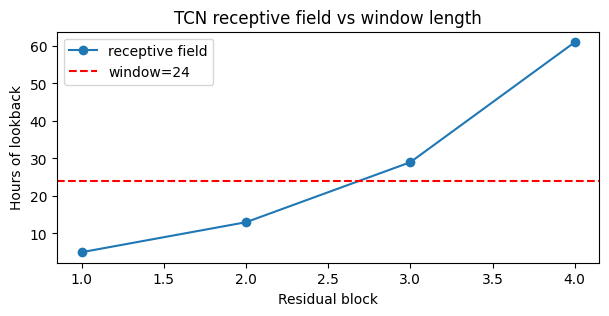

In [2]:
# A dilated causal stack can look far into the past without using the future.
# Receptive field for two kernel-3 convs per block: 1 + 2*(k-1)*sum(dilations).
from src.torch_models import TCNClassifier as _T
probe = _T(n_features=8, channels=16, kernel=3, dilations=[1, 2, 4, 8], dropout=0.0)
rf = probe.receptive_field()
WINDOW = json.load(open(PATHS["processed"] / "sequence_config.json"))["window"]
print("kernel=3, dilations=1,2,4,8, two convs/block")
print("receptive field =", rf, "window =", WINDOW)
print("covers window?", rf >= WINDOW)

# Simple table of how far each block can see.
rows = []
acc = 1
for i, d in enumerate([1, 2, 4, 8], start=1):
    acc += 2 * (3 - 1) * d
    rows.append({"block": i, "dilation": d, "receptive_field_after_block": acc})
print(pd.DataFrame(rows).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot([r["block"] for r in rows], [r["receptive_field_after_block"] for r in rows], marker="o", label="receptive field")
ax.axhline(WINDOW, color="red", linestyle="--", label=f"window={WINDOW}")
ax.set_title("TCN receptive field vs window length")
ax.set_xlabel("Residual block")
ax.set_ylabel("Hours of lookback")
ax.legend()
save_fig(fig, PATHS["figures"] / "05_tcn_receptive_field.png")
plt.show()

# Causality check: changing the future (t+1 ... T) must not change the output at time t.
# We compare last-step logits after scrambling only the *last* input vs only an earlier input.
torch.manual_seed(SEED)
x = torch.randn(4, WINDOW, 8)
mask = torch.ones(4, WINDOW)
probe.eval()
base = probe(x, mask)
x_future = x.clone()
# For last-token readout the "future" relative to the last hour does not exist inside the window.
# Check internal causality: output of the TCN *sequence* at time t should ignore t+1.
# We read the conv stack before the head by comparing two clones that differ only at the last timestep
# when we evaluate a shortened mask (as if we were at t = T-2).
mask_t = mask.clone()
mask_t[:, -1] = 0  # pretend the last hour is padding / unknown
y1 = probe(x, mask_t)
x2 = x.clone()
x2[:, -1, :] = 99.0  # junk in the "future" hour
y2 = probe(x2, mask_t)
print("max |Δlogit| when the padded future hour is scrambled:", float((y1-y2).abs().max()))
print("Causality holds if this number is ~0 (the masked last step is not used).")


**What we learned.** The stacked dilations see at least 24 hours. Zeroing/masking the last step and then scrambling it should not change the prediction — that is the causality check.


In [3]:
# Load sequence arrays. Train uses the documented patient subsample + negative downsampling; val/test stay natural.
dl = load_sequence_split(PATHS["sequences"], "dl_train")
val = load_sequence_split(PATHS["sequences"], "val")
test = load_sequence_split(PATHS["sequences"], "test")
feat_names = json.load(open(PATHS["processed"] / "sequence_feature_cols.json"))
print("features", len(feat_names), feat_names[:8], "...")

# Downsample validation *only* for the per-epoch monitor so early stopping is fast.
# Threshold selection later uses the full validation set.
rng = np.random.default_rng(SEED)
val_mon_idx = downsample_indices(val["y"], max_neg_per_pos=6.0, seed=SEED)
train_idx = downsample_indices(dl["y"], max_neg_per_pos=8.0, seed=SEED)
print("train windows used", len(train_idx), "pos_rate", dl["y"][train_idx].mean())
print("val monitor windows", len(val_mon_idx), "full val", len(val["y"]))

train_ds = WindowSequenceDataset(dl["X"], dl["y"], dl["patient_start"], dl["patient_id"], dl["hour"], WINDOW, train_idx)
val_mon_ds = WindowSequenceDataset(val["X"], val["y"], val["patient_start"], val["patient_id"], val["hour"], WINDOW, val_mon_idx)
val_ds = WindowSequenceDataset(val["X"], val["y"], val["patient_start"], val["patient_id"], val["hour"], WINDOW)
test_ds = WindowSequenceDataset(test["X"], test["y"], test["patient_start"], test["patient_id"], test["hour"], WINDOW)

n_pos = float((dl["y"][train_idx] == 1).sum())
n_neg = float((dl["y"][train_idx] == 0).sum())
pos_weight = n_neg / max(n_pos, 1.0)
print("BCE pos_weight", round(pos_weight, 3))
n_features = dl["X"].shape[1]
print("n_features", n_features)


features 72 ['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'BaseExcess'] ...
train windows used 30159 pos_rate 0.11111111
val monitor windows 12481 full val 82478
BCE pos_weight 8.0
n_features 72


## Architecture


In [4]:
# Four residual blocks, dilations 1,2,4,8, 64 channels, then last valid hour -> linear logit.
model = TCNClassifier(n_features=n_features, channels=64, kernel=3, dilations=[1, 2, 4, 8], dropout=0.3)
print(model)
print("parameters", count_parameters(model), "receptive field", model.receptive_field())


TCNClassifier(
  (tcn): Sequential(
    (0): TemporalBlock(
      (net): Sequential(
        (0): ParametrizedConv1d(
          72, 64, kernel_size=(3,), stride=(1,), padding=(2,)
          (parametrizations): ModuleDict(
            (weight): ParametrizationList(
              (0): _WeightNorm()
            )
          )
        )
        (1): Chomp1d()
        (2): ReLU()
        (3): Dropout(p=0.3, inplace=False)
        (4): ParametrizedConv1d(
          64, 64, kernel_size=(3,), stride=(1,), padding=(2,)
          (parametrizations): ModuleDict(
            (weight): ParametrizationList(
              (0): _WeightNorm()
            )
          )
        )
        (5): Chomp1d()
        (6): ReLU()
        (7): Dropout(p=0.3, inplace=False)
      )
      (downsample): Conv1d(72, 64, kernel_size=(1,), stride=(1,))
      (relu): ReLU()
    )
    (1): TemporalBlock(
      (net): Sequential(
        (0): ParametrizedConv1d(
          64, 64, kernel_size=(3,), stride=(1,), padding=(4,),

## Train


epoch 01  train_loss=1.0095  val_loss=1.4927  val_pr_auc=0.3737
epoch 02  train_loss=0.8256  val_loss=2.1585  val_pr_auc=0.3522
epoch 03  train_loss=0.7345  val_loss=2.4917  val_pr_auc=0.3272
epoch 04  train_loss=0.6586  val_loss=3.2136  val_pr_auc=0.3191
Early stopping at epoch 4 (best val PR-AUC=0.3737)


/Users/shaikniyaz/projects/CSET343_project/notebooks/05_model_tcn.ipynb:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "execution_count": null,


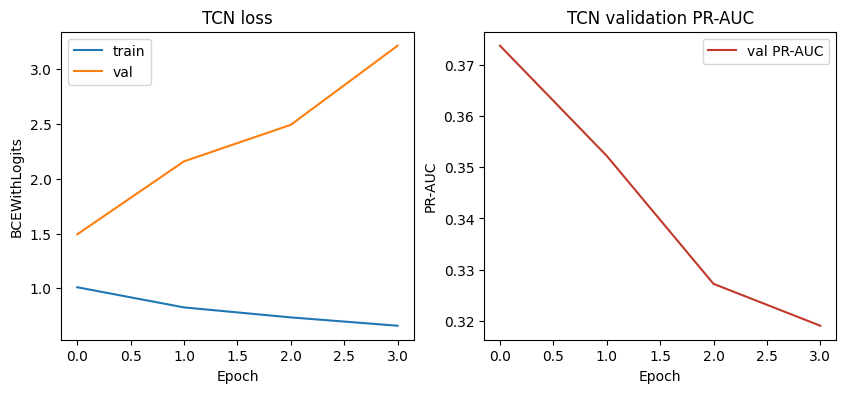

In [5]:
history = train_sequence_model(
    model, train_ds, val_mon_ds, DEVICE,
    pos_weight=pos_weight, epochs=10, patience=3, lr=1e-3, batch_size=128,
    ckpt_path=PATHS["models"] / "tcn_best.pt",
)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="val")
axes[0].set_title("TCN loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCEWithLogits")
axes[0].legend()
axes[1].plot(history["val_pr_auc"], label="val PR-AUC", color="#c0392b")
axes[1].set_title("TCN validation PR-AUC")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("PR-AUC")
axes[1].legend()
save_fig(fig, PATHS["figures"] / "05_tcn_curves.png")
plt.show()


## Threshold, test evaluation, save


threshold 0.75 val F1 0.1686 val PR-AUC 0.0868
{'roc_auc': 0.7425, 'pr_auc': 0.0836, 'precision': 0.1211, 'recall': 0.288, 'f1': 0.1705, 'specificity': 0.9532, 'accuracy': 0.9386, 'brier': 0.177, 'threshold': 0.75, 'tp': 511, 'fp': 3708, 'tn': 75501, 'fn': 1263, 'n': 80983, 'n_positive': 1774}
early detection {'n_sepsis_patients': 186, 'pct_detected': 39.784946236559136, 'pct_detected_6h_before': 26.881720430107524, 'edt_mean_hours': 40.891891891891895, 'edt_median_hours': 24.0, 'false_alarms_per_patient_day': 1.123508692194069, 'n_detected': 74}
saved /Users/shaikniyaz/projects/CSET343_project/models/tcn.pt


/Users/shaikniyaz/projects/CSET343_project/notebooks/05_model_tcn.ipynb:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "cell_type": "code",
/Users/shaikniyaz/projects/CSET343_project/notebooks/05_model_tcn.ipynb:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "id": "ae33232e",


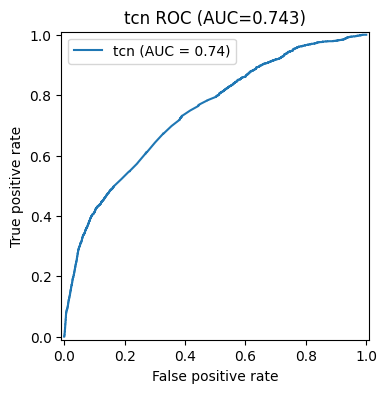

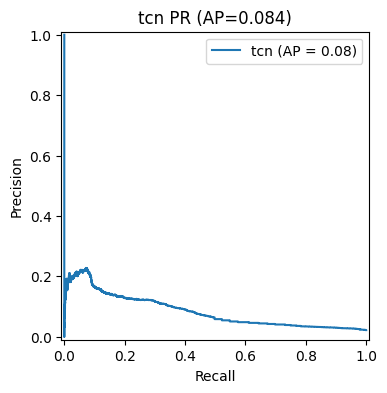

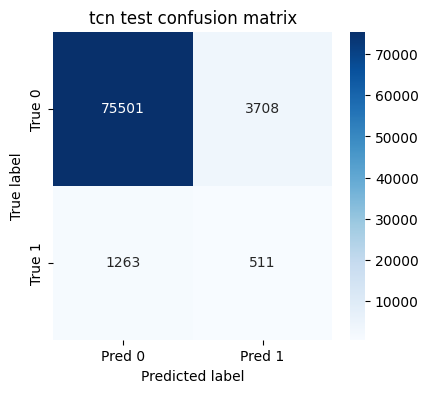

In [6]:
# Freeze the F1-max threshold on FULL validation, then score test patients only once.
p_va = predict_torch_model(model, val_ds, DEVICE, batch_size=256)
thr, val_m = choose_threshold_max_f1(val["y"], p_va)
print("threshold", round(thr, 4), "val F1", round(val_m["f1"], 4), "val PR-AUC", round(val_m["pr_auc"], 4))

t1 = time.time()
p_te = predict_torch_model(model, test_ds, DEVICE, batch_size=256)
infer_seconds = time.time() - t1
metrics = classification_metrics(test["y"], p_te, thr)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in metrics.items()})

pred_path = PATHS["results"] / "predictions_tcn.csv"
save_predictions(test["patient_id"], test["hour"], test["y"], p_te, pred_path)
edt, _ = early_detection_metrics(pd.read_csv(pred_path), "patient_id", "hour", threshold=thr)
print("early detection", edt)

plot_roc_pr(test["y"], p_te, "tcn", PATHS["figures"] / "05_tcn_roc.png", PATHS["figures"] / "05_tcn_pr.png")
plt.show()
plot_confusion_heatmap(metrics, "tcn test confusion matrix", PATHS["figures"] / "05_tcn_cm.png")
plt.show()

ckpt = PATHS["models"] / "tcn.pt"
torch.save({"state_dict": model.state_dict(), "threshold": thr, "n_features": n_features, "window": WINDOW}, ckpt)
extra = dict(
    train_seconds=history["train_seconds"], infer_seconds=infer_seconds,
    n_params=count_parameters(model), model_mb=file_size_mb(ckpt),
    **{f"edt_{k}": v for k, v in edt.items() if k != "n_sepsis_patients"},
    n_sepsis_patients=edt["n_sepsis_patients"],
)
save_metrics_table(metrics_to_row("tcn", metrics, extra), PATHS["tables"] / "metrics_tcn.csv")
print("saved", ckpt)


## Explainability


baseline PR-AUC on SHAP/permutation sample: 0.1671
     feature  pr_auc_drop
      ICULOS     0.113347
   Potassium     0.025066
Alkalinephos     0.024167
        FiO2     0.024064
     Calcium     0.020319
 HR_measured     0.017931
    Chloride     0.016013
       O2Sat     0.015200
         Age     0.014296
         SBP     0.014224
       PaCO2     0.010653
      Gender     0.009396
SHAP GradientExplainer not used (unstable or failed). Fallback = permutation importance.
reason: IndexError too many indices for tensor of dimension 1


/Users/shaikniyaz/projects/CSET343_project/notebooks/05_model_tcn.ipynb:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "**Outputs.** `models/tcn.pt`, `results/predictions_tcn.csv`, `results/tables/metrics_tcn.csv`.\n"
/Users/shaikniyaz/projects/CSET343_project/notebooks/05_model_tcn.ipynb:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "# Shared deep-learning setup: frozen splits, GPU if available, one global seed.\n",


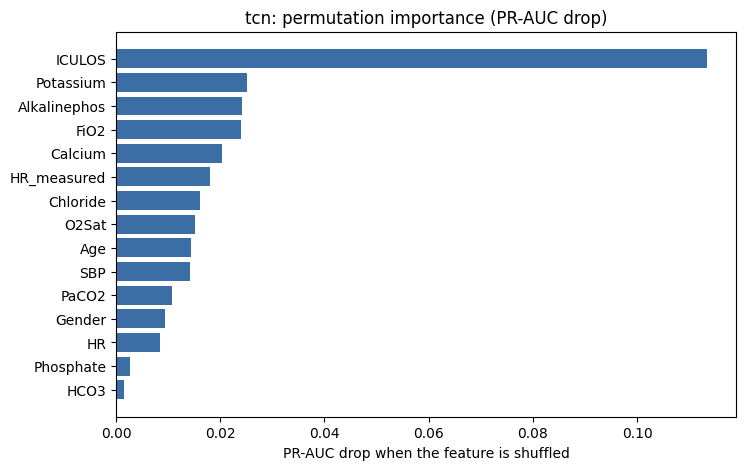

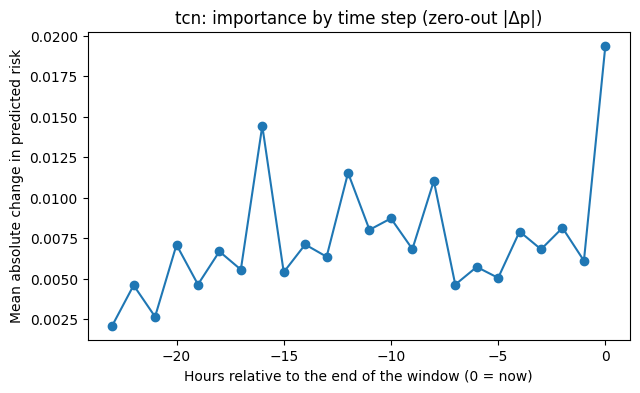

In [7]:
# Explainability: try a small SHAP GradientExplainer; if it fails or looks unstable, fall back to permutation importance.
# We also measure which hours in the 24-hour window move the prediction the most.
from sklearn.metrics import average_precision_score

imp_df, base_ap = permutation_importance_torch(model, test_ds, DEVICE, feat_names, n_samples=350, seed=SEED)
print("baseline PR-AUC on SHAP/permutation sample:", round(base_ap, 4))
print(imp_df.head(12).to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 5))
top = imp_df.head(15).iloc[::-1]
ax.barh(top["feature"], top["pr_auc_drop"], color="#3b6ea5")
ax.set_title("tcn: permutation importance (PR-AUC drop)")
ax.set_xlabel("PR-AUC drop when the feature is shuffled")
save_fig(fig, PATHS["figures"] / "05_tcn_perm_importance.png")
plt.show()

impact = time_step_importance_torch(model, test_ds, DEVICE, n_samples=350, seed=SEED)
fig, ax = plt.subplots(figsize=(7, 4))
hours_before = np.arange(-WINDOW + 1, 1)
ax.plot(hours_before, impact, marker="o")
ax.set_title("tcn: importance by time step (zero-out |Δp|)")
ax.set_xlabel("Hours relative to the end of the window (0 = now)")
ax.set_ylabel("Mean absolute change in predicted risk")
save_fig(fig, PATHS["figures"] / "05_tcn_time_importance.png")
plt.show()

# Optional SHAP on a tiny batch; skip cleanly if the explainer errors.
try:
    import shap
    from torch.utils.data import DataLoader
    bg_n = 32
    ex_n = 48
    bg_loader = DataLoader(WindowSequenceDataset(dl["X"], dl["y"], dl["patient_start"], dl["patient_id"], dl["hour"], WINDOW, train_idx[:bg_n]), batch_size=bg_n)
    ex_loader = DataLoader(WindowSequenceDataset(test["X"], test["y"], test["patient_start"], test["patient_id"], test["hour"], WINDOW, np.arange(ex_n)), batch_size=ex_n)
    bg_seq, bg_mask, _, _ = next(iter(bg_loader))
    ex_seq, ex_mask, _, _ = next(iter(ex_loader))
    # Flatten time*feature so GradientExplainer sees a 2D tensor, then wrap the model.
    class FlatWrap(torch.nn.Module):
        def __init__(self, m, t, f, mask):
            super().__init__()
            self.m, self.t, self.f, self.mask = m, t, f, mask
        def forward(self, z):
            x = z.view(-1, self.t, self.f)
            return self.m(x, self.mask.to(z.device)[:x.size(0)] if self.mask.size(0)==x.size(0) else self.mask[:1].repeat(x.size(0),1))
    model.eval()
    wrap = FlatWrap(model, WINDOW, n_features, ex_mask.to(DEVICE)).to(DEVICE)
    explainer = shap.GradientExplainer(wrap, bg_seq.to(DEVICE).reshape(bg_n, -1))
    sv = explainer.shap_values(ex_seq.to(DEVICE).reshape(ex_n, -1))
    sv = np.array(sv).reshape(ex_n, WINDOW, n_features)
    mean_abs = np.abs(sv).mean(axis=(0, 1))
    order = np.argsort(mean_abs)[-15:]
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh([feat_names[i] for i in order], mean_abs[order], color="#3b6ea5")
    ax.set_title("tcn: mean |SHAP| aggregated over time")
    ax.set_xlabel("mean |SHAP|")
    save_fig(fig, PATHS["figures"] / "05_tcn_shap_bar.png")
    plt.show()
    print("SHAP GradientExplainer succeeded on a small sample.")
except Exception as e:
    print("SHAP GradientExplainer not used (unstable or failed). Fallback = permutation importance.")
    print("reason:", type(e).__name__, str(e)[:300])


### Notebook 05 summary


In [8]:
print(pd.read_csv(PATHS["tables"] / "metrics_tcn.csv").T)
print("Done with notebook 05.")


                                          0
model                                   tcn
roc_auc                            0.742531
pr_auc                             0.083636
precision                          0.121119
recall                              0.28805
f1                                 0.170532
specificity                        0.953187
accuracy                           0.938617
brier                              0.176978
threshold                              0.75
tp                                      511
fp                                     3708
tn                                    75501
fn                                     1263
n                                     80983
n_positive                             1774
train_seconds                     92.663618
infer_seconds                     29.447781
n_params                             105601
model_mb                              0.413
edt_pct_detected                  39.784946
edt_pct_detected_6h_before      